# 05. Modelo de predicción: demanda por estación y hora

**Puntos de la rúbrica:** b (variable objetivo y características) y f (lee los resultados desde AWS).

El modelo **no es el centro del proyecto**. Sirve para una pregunta práctica: *¿se puede anticipar cuánta demanda tendrá cada estación en cada hora de la próxima semana, y un modelo de aprendizaje mejora una regla sencilla?* Si no la mejora, esa regla es la respuesta.

**Datos:** la tabla `analisis_estacion_hora` de AWS, que llena el flujo de Prefect: una fila por semana, estación y hora con `validaciones_promedio` (el promedio de los días hábiles de la semana). Hay tres semanas cargadas: 3 de agosto (4 días hábiles, por el festivo del 7), 10 de agosto y 14 de septiembre (5 días hábiles cada una).

**Variable objetivo:** `validaciones_promedio` de una estación en una hora de una semana. **Unidad de análisis:** semana x estación x hora.

**Validación temporal:** nunca se mezclan semanas al azar. Se entrena con la semana del 10 de agosto (con la del 3 de agosto como historia) y se prueba con la del 14 de septiembre (con las dos semanas de agosto como historia).

| # | Paso | Qué responde |
|---|---|---|
| 1 | Datos desde AWS | ¿Qué hay en la tabla? |
| 2 | Variables y validación | ¿Qué se predice y con qué información? |
| 3 | Líneas base | ¿Qué tan bien predicen reglas simples? |
| 4 | Modelos de aprendizaje | ¿Un modelo mejora la línea base? |
| 5 | Conclusiones | ¿Qué se concluye y qué limita el resultado? |


## 1. Datos desde AWS

El notebook solo **lee** de la base, con el usuario de solo lectura. Las credenciales salen del archivo `.env`, que no se sube a GitHub.


In [1]:
# QUÉ HACE: lee de AWS la tabla analisis_estacion_hora con el usuario de solo lectura y resume qué contiene.
# CÓMO: las credenciales salen del archivo .env (nunca del código); se descargan solo las columnas necesarias y no se escribe nada en la base.
# QUÉ MIRAR: tres semanas, cuántas estaciones tiene cada una y cuántos días hábiles se promediaron; la suma de validaciones_promedio de todas las filas de una semana es la demanda de un día hábil típico.
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
FIGS = Path('../docs/figs'); FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'legend.frameon': False})
COLS_SEM = ['#8a8a85', '#eb6834', '#2a78d6']

load_dotenv(Path('../.env'))
engine = create_engine(URL.create('postgresql+psycopg2', username=os.environ['DB_READONLY_USER'], password=os.environ['DB_READONLY_PASSWORD'],
                                  host=os.environ['DB_HOST'], port=int(os.getenv('DB_PORT', '5432')), database=os.environ['DB_NAME']),
                       connect_args={'sslmode': os.getenv('DB_SSLMODE', 'require')})
datos = pd.read_sql(text('SELECT semana_inicio, cod_estacion, hora, nombre_estacion, validaciones_promedio, dias_usados FROM analisis_estacion_hora'), engine)
datos['semana_inicio'] = pd.to_datetime(datos['semana_inicio'])
print(f"{len(datos):,} filas leídas de AWS".replace(',', '.'))
datos.groupby('semana_inicio').agg(estaciones=('cod_estacion', 'nunique'), filas=('hora', 'size'), dias_habiles=('dias_usados', 'max'),
                                   validaciones_por_dia_habil=('validaciones_promedio', 'sum')).round(0)


10.776 filas leídas de AWS


,estaciones,filas,dias_habiles,validaciones_por_dia_habil
semana_inicio,,,,
2026-08-03,147,3528,4,1856992.0
2026-08-10,151,3624,5,1820300.0
2026-09-14,151,3624,5,1880420.0


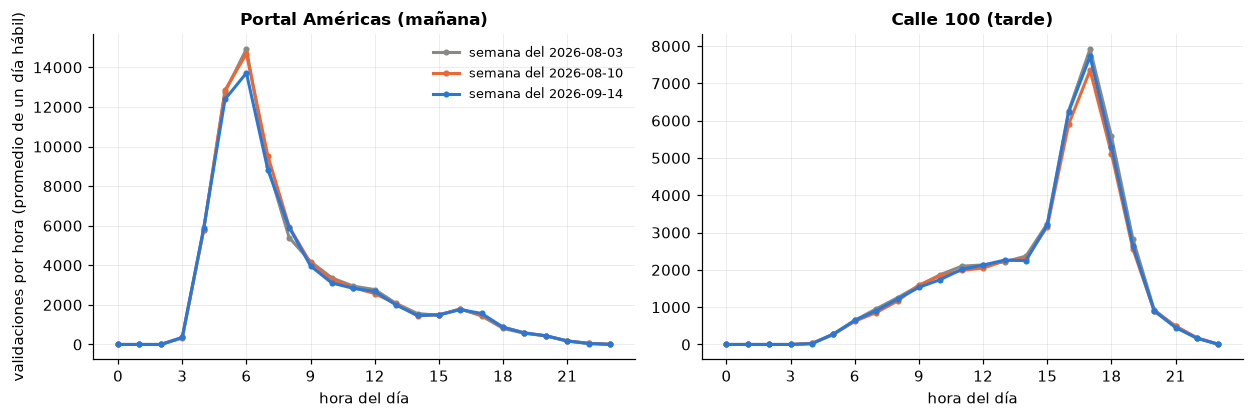

In [2]:
# QUÉ HACE: dibuja la demanda por hora de dos estaciones en las tres semanas, para ver cuánto se parecen entre semanas.
# CÓMO: una línea por semana con validaciones_promedio de cada hora; Portal Américas es una estación de la mañana y Calle 100, de la tarde.
# QUÉ MIRAR: las tres semanas tienen casi la misma forma y el mismo pico; por eso una regla simple (repetir la semana anterior) ya predice muy bien.
ancho = datos.pivot_table(index=['cod_estacion', 'hora'], columns='semana_inicio', values='validaciones_promedio')
ancho.columns = [c.strftime('%Y-%m-%d') for c in ancho.columns]
SEM = list(ancho.columns)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=False)
for ax, (nombre, cod) in zip(axes, {'Portal Américas (mañana)': '05000', 'Calle 100 (tarde)': '02300'}.items()):
    for s, color in zip(SEM, COLS_SEM):
        ax.plot(ancho.loc[cod].index, ancho.loc[cod, s], color=color, lw=2, marker='o', ms=3, label=f"semana del {s}")
    ax.set_title(nombre); ax.set_xlabel('hora del día'); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel('validaciones por hora (promedio de un día hábil)'); axes[0].legend(fontsize=8.5)
plt.tight_layout(); plt.savefig(FIGS / '05_curvas_semanas.png', bbox_inches='tight'); plt.show()


## 2. Qué se predice y con qué información

Para cada estación y hora de una **semana objetivo** se predice `validaciones_promedio`. La información disponible es solo la de semanas **anteriores**:

| Variable | Qué es |
|---|---|
| `semana_anterior` | Valor de la misma estación y hora en la semana inmediatamente anterior |
| `promedio_historico` | Promedio de la misma estación y hora en todas las semanas anteriores |
| `hora` | Hora del día (0 a 23) |

Nunca se usa información de la semana objetivo. Con tres semanas hay una sola prueba temporal, que es la más honesta posible:

| | Semana objetivo | Historia |
|---|---|---|
| **Entrenamiento** | 10 de agosto | 3 de agosto |
| **Prueba** | 14 de septiembre | 3 y 10 de agosto |


In [3]:
# QUÉ HACE: arma las tablas de entrenamiento y de prueba: una fila por estación y hora con el valor a predecir y las variables de semanas anteriores.
# CÓMO: para la semana objetivo se toma como historia solo lo anterior; se descartan las estaciones que no existían en la semana de historia (no hay con qué predecirlas).
# QUÉ MIRAR: cuántas filas quedan en cada tabla y qué parte de las celdas son de alta presión (1.000 validaciones por hora o más), que es donde importa acertar.
def armar(objetivo, historia):
    d = pd.DataFrame({'y': ancho[objetivo], 'semana_anterior': ancho[historia[-1]], 'promedio_historico': ancho[historia].mean(axis=1)}).reset_index()
    n0 = len(d); d = d.dropna(subset=['y', 'semana_anterior']).reset_index(drop=True)
    return d, n0 - len(d)
entrenamiento, perd_e = armar(SEM[1], SEM[:1])
prueba, perd_p = armar(SEM[2], SEM[:2])
for nombre, d, perd in [('entrenamiento (10-ago)', entrenamiento, perd_e), ('prueba (14-sep)', prueba, perd_p)]:
    print(f"{nombre}: {len(d):,} filas ({perd} descartadas por estación sin historia); alta presión (>= 1.000): {(d['y'] >= 1000).mean() * 100:.1f} % de las filas; demanda media por fila: {d['y'].mean():.0f}".replace(',', '.'))
prueba.head()


entrenamiento (10-ago): 3.528 filas (144 descartadas por estación sin historia); alta presión (>= 1.000): 12.7 % de las filas; demanda media por fila: 516
prueba (14-sep): 3.576 filas (96 descartadas por estación sin historia); alta presión (>= 1.000): 13.1 % de las filas; demanda media por fila: 517


,cod_estacion,hora,y,semana_anterior,promedio_historico
0,02000,0,0.4,0.2,0.2
1,02000,1,0.0,0.0,0.0
2,02000,2,0.0,0.0,0.0
3,02000,3,0.0,0.0,0.0
4,02000,4,675.6,597.8,585.0


## 3. Líneas base

Antes de un modelo se prueban reglas que no aprenden nada:

- **A. Semana anterior:** la predicción es el valor de la misma estación y hora de la semana pasada.
- **B. Promedio histórico:** la predicción es el promedio de todas las semanas anteriores para esa estación y hora.

Métricas (sobre la semana de prueba): **MAE** (error absoluto medio, en validaciones por hora), **RMSE** (penaliza más los errores grandes) y **R²** (parte de la variación que se explica). Como lo que importa son las horas con presión, se repiten **solo para las filas de alta presión** (1.000 validaciones por hora o más), junto con el **error relativo mediano**.


In [4]:
# QUÉ HACE: calcula las métricas de las dos líneas base sobre la semana de prueba, para todas las filas y solo para las de alta presión.
# CÓMO: error = predicción - valor real; MAE y RMSE en validaciones por hora; R² frente al promedio; error relativo = |error| / valor real, con su mediana.
# QUÉ MIRAR: cuál de las dos reglas se equivoca menos y cuánto es ese error en las horas que importan.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
def metricas(y, p, alta=None):
    m = np.ones(len(y), bool) if alta is None else alta
    pos = m & (y > 0)                                                                         # el error relativo no existe donde la demanda real es 0
    return {'MAE': mean_absolute_error(y[m], p[m]), 'RMSE': mean_squared_error(y[m], p[m]) ** 0.5, 'R²': r2_score(y[m], p[m]),
            'error relativo mediano (%)': float(np.median(np.abs(p[pos] - y[pos]) / y[pos]) * 100)}
y_p = prueba['y'].values; alta_p = y_p >= 1000
BASES = {'A. semana anterior': prueba['semana_anterior'].values, 'B. promedio histórico': prueba['promedio_historico'].values}
filas = {}
for nombre, pred in BASES.items():
    filas[(nombre, 'todas las filas')] = metricas(y_p, pred)
    filas[(nombre, 'alta presión (>= 1.000)')] = metricas(y_p, pred, alta_p)
tabla_base = pd.DataFrame(filas).T
print(f"Semana de prueba: {len(prueba):,} filas, {alta_p.sum()} de alta presión".replace(',', '.'))
tabla_base.round(2)


Semana de prueba: 3.576 filas. 469 de alta presión


MAE    RMSE    R²  error relativo mediano (%)
A. semana anterior    todas las filas           41.19  109.79  0.99                        6.74
                      alta presión (>= 1.000)  167.77  264.61  0.98                        4.43
B. promedio histórico todas las filas           38.08  104.43  0.99                        6.25
                      alta presión (>= 1.000)  152.93  251.14  0.98                        3.92

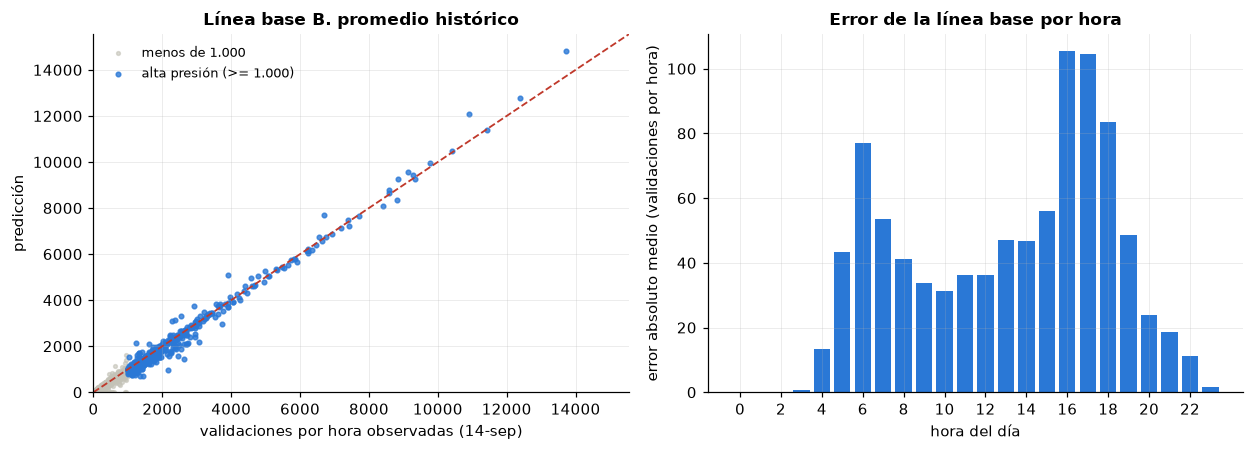

In [5]:
# QUÉ HACE: dibuja lo predicho frente a lo real para la mejor línea base y el error por hora del día.
# CÓMO: izquierda, un punto por estación y hora (predicción del promedio histórico contra lo observado; la diagonal es el acierto perfecto); derecha, el error absoluto medio por hora del día.
# QUÉ MIRAR: los puntos pegados a la diagonal; si el error crece donde la demanda es mayor (horas de punta).
mejor = min(BASES, key=lambda k: metricas(y_p, BASES[k], alta_p)['MAE']); pred = BASES[mejor]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axes[0]; lim = max(y_p.max(), pred.max()) * 1.05
ax.scatter(y_p[~alta_p], pred[~alta_p], s=6, color='#c3c2b7', alpha=0.6, label='menos de 1.000')
ax.scatter(y_p[alta_p], pred[alta_p], s=9, color='#2a78d6', alpha=0.8, label='alta presión (>= 1.000)')
ax.plot([0, lim], [0, lim], color='#c0392b', lw=1.2, ls='--'); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('validaciones por hora observadas (14-sep)'); ax.set_ylabel('predicción'); ax.set_title(f"Línea base {mejor}"); ax.legend(fontsize=8.5)
ax = axes[1]; err = pd.Series(np.abs(pred - y_p)).groupby(prueba['hora'].values).mean()
ax.bar(err.index, err.values, color='#2a78d6', width=0.8); ax.set_xlabel('hora del día'); ax.set_ylabel('error absoluto medio (validaciones por hora)'); ax.set_xticks(range(0, 24, 2))
ax.set_title('Error de la línea base por hora')
plt.tight_layout(); plt.savefig(FIGS / '05_linea_base.png', bbox_inches='tight'); plt.show()


### Lectura de las líneas base

- Las dos reglas simples predicen muy bien: **R² de 0,98 a 0,99** en la semana de prueba. Era esperable, porque la forma de la demanda por hora se repite de una semana a otra (figura de las tres semanas).
- **El promedio histórico (B) es un poco mejor que repetir la semana anterior (A):** MAE de 38 contra 41 validaciones por hora en todas las filas, y de 153 contra 168 en las 469 filas de alta presión; el error relativo mediano en alta presión es de 3,9 % contra 4,4 %. Promediar varias semanas reduce el ruido de una semana atípica.
- El error absoluto es mayor en las horas de punta (6 h y 16 a 18 h), donde la demanda es mayor; en términos relativos sigue siendo bajo.
- **Esta es la vara que debe superar un modelo:** MAE de 153 validaciones por hora y error relativo mediano de 3,9 % en las horas de alta presión.


## 4. Modelos de aprendizaje

Se prueban dos modelos con las mismas tres variables (`semana_anterior`, `promedio_historico` y `hora`) y se comparan con las líneas base en la **misma semana de prueba**:

- **C. Regresión lineal:** la predicción es una combinación lineal de las variables.
- **D. Bosque aleatorio pequeño:** 100 árboles de profundidad máxima 6 y al menos 10 filas por hoja; es pequeño a propósito para no sobreajustar con una sola semana de entrenamiento.

**Limitación que conviene tener presente:** en el entrenamiento solo hay una semana de historia, así que `promedio_historico` y `semana_anterior` son iguales; en la prueba, en cambio, el promedio usa dos semanas. El modelo no puede aprender cuánto pesar cada una. Es una consecuencia de tener tres semanas, no de la elección del modelo.

Además de las métricas de error, se revisa lo que importa para el proyecto: **si la predicción reproduce el ranking de estaciones** de cada franja. Para la semana de prueba se calcula la carga sobre el umbral de 1.000 (la misma del notebook 04) con lo observado y con lo predicho, y se cuenta cuántas de las 10 estaciones primeras reales aparecen entre las 10 primeras predichas.


In [6]:
# QUÉ HACE: entrena dos modelos con la semana de entrenamiento y los compara con las líneas base en la semana de prueba.
# CÓMO: regresión lineal y bosque aleatorio pequeño con tres variables (semana_anterior, promedio_historico y hora); las predicciones negativas se llevan a 0; las métricas son las mismas de las líneas base.
# QUÉ MIRAR: si algún modelo se equivoca menos que el promedio histórico (B) en las horas de alta presión.
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
VARS = ['semana_anterior', 'promedio_historico', 'hora']
X_e, y_e, X_p = entrenamiento[VARS].values, entrenamiento['y'].values, prueba[VARS].values
modelos = {'C. regresión lineal': LinearRegression(),
           'D. bosque aleatorio (pequeño)': RandomForestRegressor(n_estimators=100, max_depth=6, min_samples_leaf=10, random_state=0, n_jobs=-1)}
PRED = dict(BASES)
for nombre, m in modelos.items():
    m.fit(X_e, y_e); PRED[nombre] = np.clip(m.predict(X_p), 0, None)
filas = {}
for nombre, pred in PRED.items():
    filas[(nombre, 'todas las filas')] = metricas(y_p, pred)
    filas[(nombre, 'alta presión (>= 1.000)')] = metricas(y_p, pred, alta_p)
tabla_modelos = pd.DataFrame(filas).T
tabla_modelos.round(2)


MAE    RMSE    R²  error relativo mediano (%)
A. semana anterior            todas las filas           41.19  109.79  0.99                        6.74
                              alta presión (>= 1.000)  167.77  264.61  0.98                        4.43
B. promedio histórico         todas las filas           38.08  104.43  0.99                        6.25
                              alta presión (>= 1.000)  152.93  251.14  0.98                        3.92
C. regresión lineal           todas las filas           42.02  107.98  0.99                        7.24
                              alta presión (>= 1.000)  172.22  260.62  0.98                        4.73
D. bosque aleatorio (pequeño) todas las filas           47.70  159.55  0.98                        7.37
                              alta presión (>= 1.000)  215.99  416.27  0.95                        5.75

In [7]:
# QUÉ HACE: revisa si cada método reproduce el ranking de estaciones de la semana de prueba, en la punta de la mañana y en la de la tarde.
# CÓMO: carga sobre el umbral = suma, hora a hora dentro de la franja, de lo que la demanda excede 1.000 validaciones por hora; se calcula con lo observado y con lo predicho; se cuentan los aciertos en las 10 primeras estaciones y se mide la correlación de Spearman entre los dos rankings.
# QUÉ MIRAR: cuántas de las 10 primeras estaciones reales se recuperan con cada método y qué tan parecido es el orden completo.
from scipy.stats import spearmanr
FRANJA_H = {'mañana': (5, 8), 'tarde': (16, 19)}
def carga(valores):
    d = prueba[['cod_estacion', 'hora']].assign(v=valores)
    return {f: d[d['hora'].between(a, z)].assign(c=lambda x: (x['v'] - 1000).clip(lower=0)).groupby('cod_estacion')['c'].sum() for f, (a, z) in FRANJA_H.items()}
real = carga(y_p)
filas = {}
for nombre, pred in PRED.items():
    cp = carga(pred)
    for f in FRANJA_H:
        r, q = real[f], cp[f]; activas = r[r > 0].index
        filas[(nombre, f)] = {'aciertos en las 10 primeras': len(set(r.nlargest(10).index) & set(q.nlargest(10).index)),
                              'Spearman (estaciones con carga)': spearmanr(r[activas], q[activas])[0]}
tabla_rank = pd.DataFrame(filas).T
tabla_rank.round(3)


aciertos en las 10 primeras  Spearman (estaciones con carga)
A. semana anterior            mañana                         10.0                            0.990
                              tarde                           8.0                            0.950
B. promedio histórico         mañana                         10.0                            0.994
                              tarde                           8.0                            0.963
C. regresión lineal           mañana                         10.0                            0.992
                              tarde                           8.0                            0.961
D. bosque aleatorio (pequeño) mañana                         10.0                            0.992
                              tarde                           8.0                            0.960

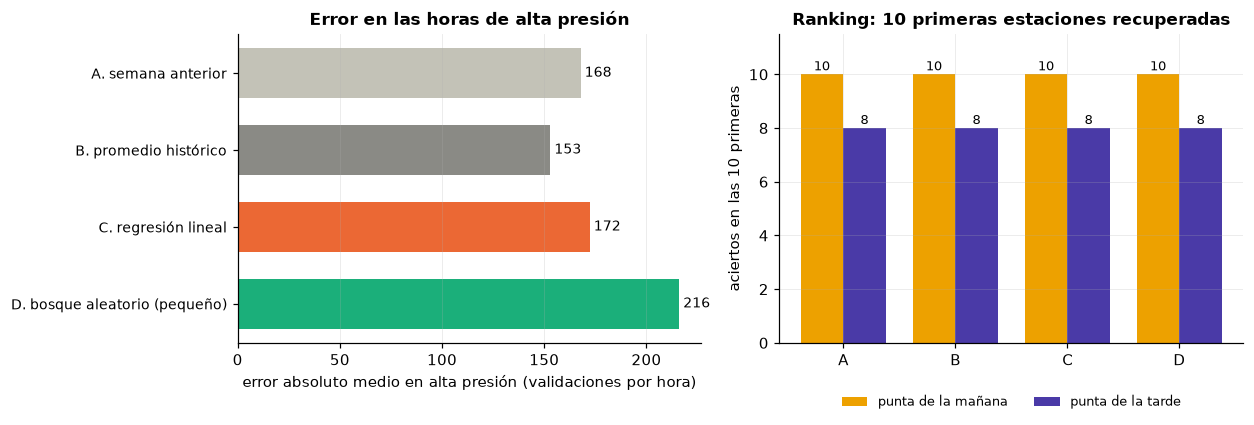

In [8]:
# QUÉ HACE: resume en dos gráficas cuál método se equivoca menos y cuál reproduce mejor el ranking de estaciones.
# CÓMO: izquierda, error absoluto medio en las horas de alta presión (menos es mejor); derecha, cuántas de las 10 primeras estaciones reales aparecen entre las 10 primeras predichas, por franja.
# QUÉ MIRAR: si algún modelo mejora a las líneas base en el error o en el ranking, y por cuánto.
metodos = list(PRED); colores = ['#c3c2b7', '#8a8a85', '#eb6834', '#1baf7a']
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
ax = axes[0]; mae = [metricas(y_p, PRED[k], alta_p)['MAE'] for k in metodos]
ax.barh(range(len(metodos))[::-1], mae, color=colores, height=0.65)
for i, v in zip(range(len(metodos))[::-1], mae): ax.text(v + 2, i, f"{v:.0f}", va='center', fontsize=9)
ax.set_yticks(range(len(metodos))[::-1]); ax.set_yticklabels(metodos, fontsize=9); ax.set_xlabel('error absoluto medio en alta presión (validaciones por hora)'); ax.set_title('Error en las horas de alta presión'); ax.grid(axis='y', visible=False)
ax = axes[1]; x = np.arange(len(metodos)); w = 0.38
for j, (f, c) in enumerate({'mañana': '#eda100', 'tarde': '#4a3aa7'}.items()):
    v = [tabla_rank.loc[(k, f), 'aciertos en las 10 primeras'] for k in metodos]
    ax.bar(x + (j - 0.5) * w, v, w, color=c, label=f"punta de la {f}")
    for xi, vi in zip(x + (j - 0.5) * w, v): ax.text(xi, vi + 0.15, f"{vi:.0f}", ha='center', fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([k.split('.')[0] for k in metodos]); ax.set_ylim(0, 11.5); ax.set_ylabel('aciertos en las 10 primeras'); ax.set_title('Ranking: 10 primeras estaciones recuperadas'); ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)
plt.tight_layout(); plt.savefig(FIGS / '05_comparacion_metodos.png', bbox_inches='tight'); plt.show()


### Lectura del modelo

- **Ningún modelo supera al promedio histórico.** En las horas de alta presión el MAE es 153 (promedio histórico), 172 (regresión lineal) y 216 (bosque aleatorio); el error relativo mediano, 3,9 %, 4,7 % y 5,8 %. En todas las filas pasa lo mismo (38, 42 y 48). El bosque aleatorio es el peor, sobre todo en los picos (RMSE de 416 contra 251): con una semana de entrenamiento no ve suficientes picos distintos.
- **El ranking de estaciones se recupera con cualquier método.** Las 10 primeras de la mañana coinciden 10 de 10 y las de la tarde 8 de 10 con los cuatro métodos, y el orden completo es casi igual (Spearman de 0,95 a 0,99). Para decidir qué estaciones reforzar, repetir la semana anterior ya basta.
- **Resultado:** se queda el **promedio histórico como método de predicción**. Es simple, se explica en una línea y no pierde frente a un modelo de aprendizaje. Con tres semanas (una sola de entrenamiento) no hay datos para esperar más; con más semanas cargadas por el flujo se puede repetir la prueba.


## 5. Conclusiones

1. **Datos y método.** El modelo lee de AWS la tabla `analisis_estacion_hora` (10.776 filas, tres semanas) y predice la demanda de un día hábil típico por estación y hora, con validación temporal: entrena con la semana del 10 de agosto y prueba con la del 14 de septiembre.
2. **Líneas base.** Repetir la semana anterior o promediar las semanas anteriores predice con R² de 0,98 a 0,99. El promedio histórico es mejor: error absoluto medio de 153 validaciones por hora en las horas de alta presión y error relativo mediano de 3,9 %.
3. **Modelos.** Ni la regresión lineal (error de 172) ni un bosque aleatorio pequeño (216) mejoran al promedio histórico.
4. **Ranking de estaciones.** Los cuatro métodos recuperan las 10 primeras estaciones de la mañana (10 de 10) y 8 de las 10 de la tarde. Para priorizar estaciones basta una regla simple.
5. **Decisión.** El método de predicción del proyecto es el **promedio histórico por estación y hora**.

**Limitaciones**

- Solo hay tres semanas: una de entrenamiento y una de prueba. Hay una sola prueba temporal, así que no se puede medir qué tanto varía el resultado.
- Las semanas de agosto y la de septiembre no son consecutivas.
- En el entrenamiento el promedio histórico y la semana anterior coinciden (hay una sola semana de historia), por lo que los modelos no aprenden a pesarlos.
- No hay variables externas (clima, eventos, puentes festivos) ni datos del componente zonal.
- La predicción es del promedio de un día hábil, no de un día específico.

**Trabajo futuro:** a medida que el flujo cargue más semanas, repetir la prueba con varias semanas de entrenamiento y varias pruebas temporales; probar variables de calendario (festivos, puentes) y revisar las estaciones que cambian de régimen.
